In [83]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import os
from ne_aligned_utils.plot import plot_aligned_embedding
from ne_aligned_utils.data import make_joint_gmm
from ne_aligned_utils.utils import sparsify_affinities

from openTSNE import TSNE
from openTSNE.affinity import Affinities
import scipy.sparse as sp
from sklearn.decomposition import PCA


env: CUDA_VISIBLE_DEVICES=1
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
dataset = "gmm"
tol = 1e-12
maxIter = int(1e4)
thetas = [1.0, 2.0, 3.0]

n0 = 600
n1 = 600
colors =  np.array(["r"]*n0 + ["b"]*n1)
seeds = [0, 1, 2, 3, 4]
seed = 0
eps_times_list = [1, 10, 100]


res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)
fig_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned/figures"

In [204]:
# general for NE experiments
init_str = "random"  # "pca" or "random"
init_scale = 1

batch_size = 2**14
negative_samples = 5
n_epochs = 200
loss_mode = "infonce"

In [3]:
# 2d first
embd_dim = 2


In [206]:
# sample non-sparsified

alignment = True
sample_pos = "per_point"
sparsify = None


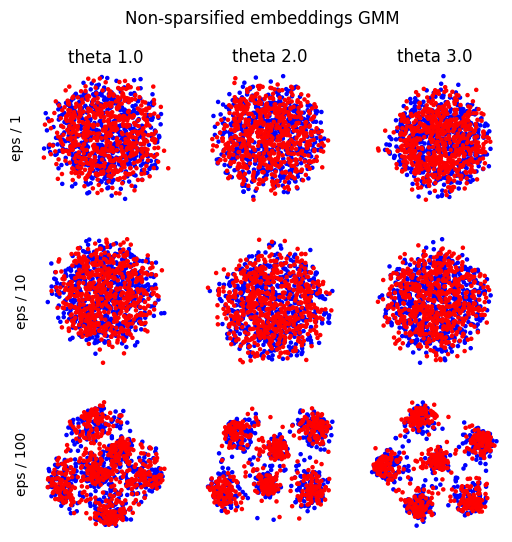

In [207]:

fig, ax = plt.subplots(len(thetas), len(eps_times_list), figsize=(6, 6))

for j, theta in enumerate(thetas):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_theta_{theta}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                            f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                            f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               )
        if i == 0:
            ax[i, j].set_title(f"theta {theta}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle(f"Non-sparsified embeddings GMM")
fig.savefig(os.path.join(fig_path, f"gmm_nonsparsified.png"))

In [208]:
concordances_sample = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
rand_sample = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
for i, theta in enumerate(thetas):
    for j, eps_times in enumerate(eps_times_list):
        metrics_path = os.path.join(res_path,
                                    f"{dataset}_theta_{theta}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                                    f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                                    f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}_metrics.npz")
        metrics = np.load(metrics_path)
        concordances_sample[i, j] = metrics["concordance"]
        rand_sample[i, j] = metrics["rand"]


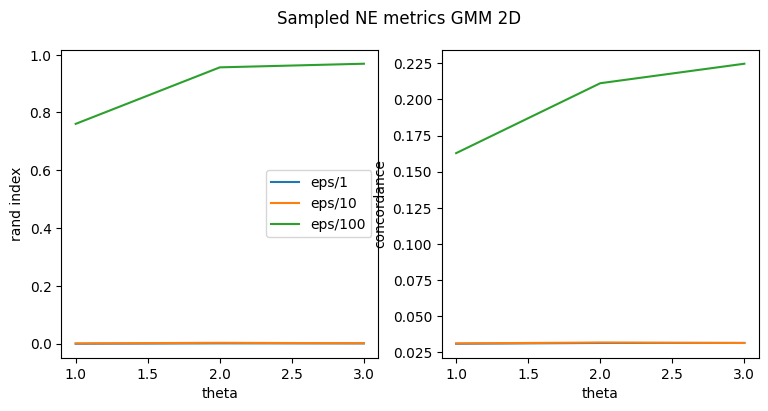

In [209]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))

for i, eps_times in enumerate(eps_times_list):
    ax[0].plot(thetas, rand_sample[:, i].mean(-1), label=f"eps/{eps_times}")
    ax[1].plot(thetas, concordances_sample[:, i].mean(-1), label=f"eps/{eps_times}")

ax[0].set_xlabel("theta")
ax[0].set_ylabel("rand index")
ax[0].legend()
ax[1].set_xlabel("theta")
ax[1].set_ylabel("concordance")


fig.suptitle(f"Sampled NE metrics GMM 2D")
fig.savefig(os.path.join(fig_path, f"gmm_sample_metrics_2d.png"))

In [210]:
# iterate over sparsified

alignment = True
sample_pos = None
sparsify = "topk"


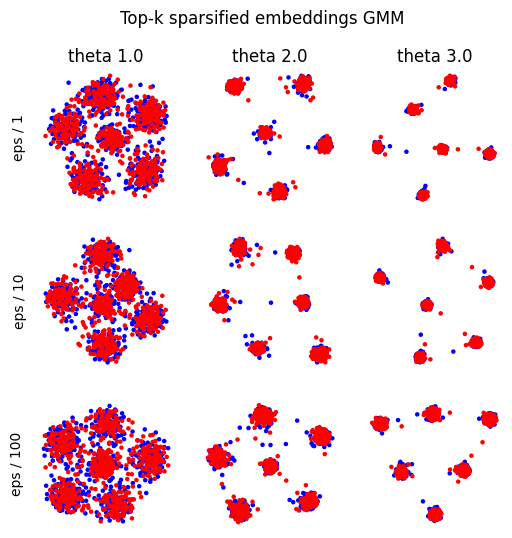

In [211]:

fig, ax = plt.subplots(len(thetas), len(eps_times_list), figsize=(6, 6))

for j, theta in enumerate(thetas):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_theta_{theta}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                            f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                            f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               )
        if i == 0:
            ax[i, j].set_title(f"theta {theta}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle(f"Top-k sparsified embeddings GMM")
fig.savefig(os.path.join(fig_path, f"gmm_topk.png"))

In [212]:
concordances_topk = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
rand_topk = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
for i, theta in enumerate(thetas):
    for j, eps_times in enumerate(eps_times_list):
        metrics_path = os.path.join(res_path,
                                    f"{dataset}_theta_{theta}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                                    f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                                    f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}_metrics.npz")
        metrics = np.load(metrics_path)
        concordances_topk[i, j] = metrics["concordance"]
        rand_topk[i, j] = metrics["rand"]




In [213]:
rand_topk.shape

(3, 3, 5)

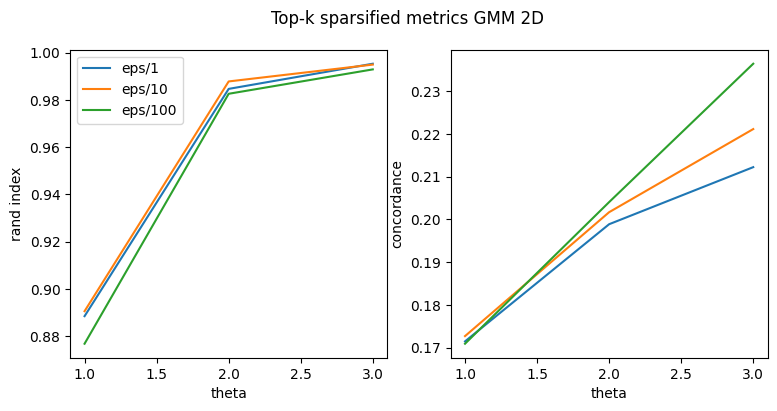

In [214]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))

for i, eps_times in enumerate(eps_times_list):
    ax[0].plot(thetas, rand_topk[:, i].mean(-1), label=f"eps/{eps_times}")
    ax[1].plot(thetas, concordances_topk[:, i].mean(-1), label=f"eps/{eps_times}")

ax[0].set_xlabel("theta")
ax[0].set_ylabel("rand index")
ax[0].legend()
ax[1].set_xlabel("theta")
ax[1].set_ylabel("concordance")


fig.suptitle(f"Top-k sparsified metrics GMM 2D")
fig.savefig(os.path.join(fig_path, f"gmm_topk_metrics_2d.png"))

In [215]:
# EOT
sparsify = None # "topk" # None # "topk" # None


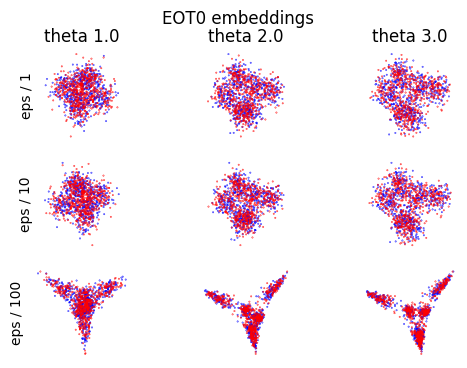

In [216]:
t=0

fig, ax = plt.subplots( len(thetas), len(thetas), figsize=(6, 4))

for j, theta in enumerate(thetas):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_theta_{theta}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               s=0.1,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               )
        if i == 0:
            ax[i, j].set_title(f"theta {theta}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)
fig.suptitle(f"EOT{t} embeddings")
fig.savefig(os.path.join(fig_path, f"gmm_EOT{t}.png"))

In [217]:
concordances_eot0 = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
rand_eot0 = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
for i, theta in enumerate(thetas):
    for j, eps_times in enumerate(eps_times_list):
        metrics_path = os.path.join(res_path,
                                    f"{dataset}_theta_{theta}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}_metrics.npz")
        metrics = np.load(metrics_path)
        concordances_eot0[i, j] = metrics["concordance"]
        rand_eot0[i, j] = metrics["rand"]


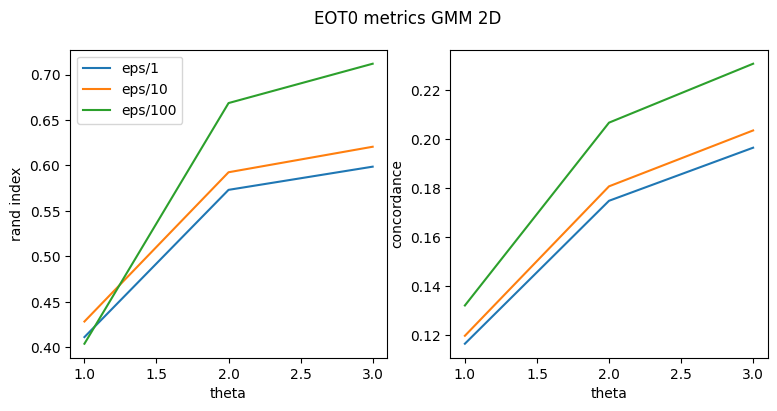

In [218]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))

for i, eps_times in enumerate(eps_times_list):
    ax[0].plot(thetas, rand_eot0[:, i].mean(-1), label=f"eps/{eps_times}")
    ax[1].plot(thetas, concordances_eot0[:, i].mean(-1), label=f"topk eps/{eps_times}")

ax[0].set_xlabel("theta")
ax[0].set_ylabel("rand index")
ax[0].legend()
ax[1].set_xlabel("theta")
ax[1].set_ylabel("concordance")

fig.suptitle(f"EOT{t} metrics GMM 2D")
fig.savefig(os.path.join(fig_path, f"gmm_EOT{t}_metrics_2d.png"))

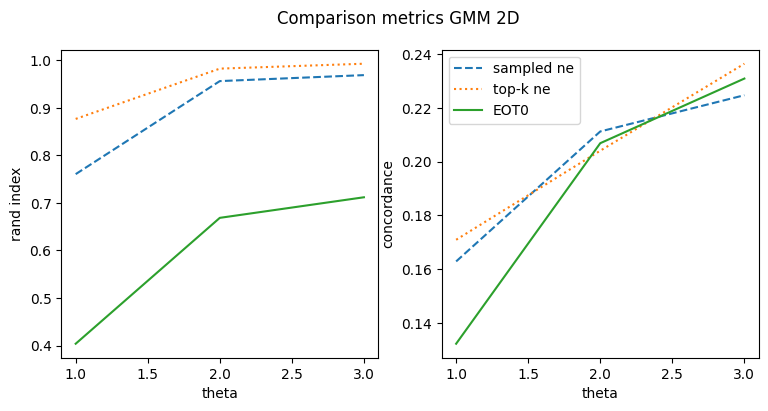

In [219]:
# comparison plot
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].plot(thetas, rand_sample[:, -1].mean(-1), label=f"sampled ne", linestyle="dashed")
ax[0].plot(thetas, rand_topk[:, -1].mean(-1), label=f"top-k ne", linestyle="dotted")
ax[0].plot(thetas, rand_eot0[:, -1].mean(-1), label=f"EOT0 ", linestyle="solid")

ax[1].plot(thetas, concordances_sample[:, -1].mean(-1), label=f"sampled ne", linestyle="dashed")
ax[1].plot(thetas, concordances_topk[:, -1].mean(-1), label=f"top-k ne", linestyle="dotted")
ax[1].plot(thetas, concordances_eot0[:, -1].mean(-1), label=f"EOT0", linestyle="solid")

ax[0].set_xlabel("theta")
ax[0].set_ylabel("rand index")
ax[1].legend()
ax[1].set_xlabel("theta")
ax[1].set_ylabel("concordance")

fig.suptitle(f"Comparison metrics GMM 2D")
fig.savefig(os.path.join(fig_path, f"gmm_comparison_metrics_2d.png"))

In [220]:
# 6d
embd_dim = 6

In [221]:
# sample non-sparsified

alignment = True
sample_pos = "per_point"
sparsify = None


In [222]:
concordances_sample = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
rand_sample = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
for i, theta in enumerate(thetas):
    for j, eps_times in enumerate(eps_times_list):
        metrics_path = os.path.join(res_path,
                                    f"{dataset}_theta_{theta}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                                    f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                                    f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}_metrics.npz")
        metrics = np.load(metrics_path)
        concordances_sample[i, j] = metrics["concordance"]
        rand_sample[i, j] = metrics["rand"]


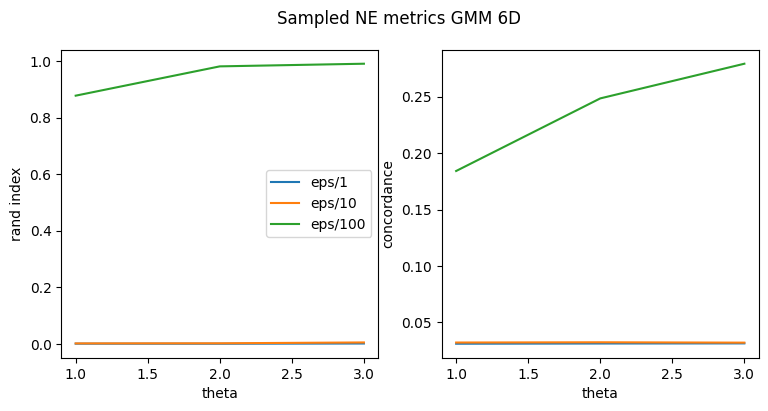

In [223]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))

for i, eps_times in enumerate(eps_times_list):
    ax[0].plot(thetas, rand_sample[:, i].mean(-1), label=f"eps/{eps_times}")
    ax[1].plot(thetas, concordances_sample[:, i].mean(-1), label=f"eps/{eps_times}")

ax[0].set_xlabel("theta")
ax[0].set_ylabel("rand index")
ax[0].legend()
ax[1].set_xlabel("theta")
ax[1].set_ylabel("concordance")


fig.suptitle(f"Sampled NE metrics GMM 6D")
fig.savefig(os.path.join(fig_path, f"gmm_sample_metrics_6d.png"))

In [224]:
# iterate over sparsified

alignment = True
sample_pos = None
sparsify = "topk"


In [225]:
concordances_topk = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
rand_topk = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
for i, theta in enumerate(thetas):
    for j, eps_times in enumerate(eps_times_list):
        metrics_path = os.path.join(res_path,
                                    f"{dataset}_theta_{theta}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                                    f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                                    f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}_metrics.npz")
        metrics = np.load(metrics_path)
        concordances_topk[i, j] = metrics["concordance"]
        rand_topk[i, j] = metrics["rand"]



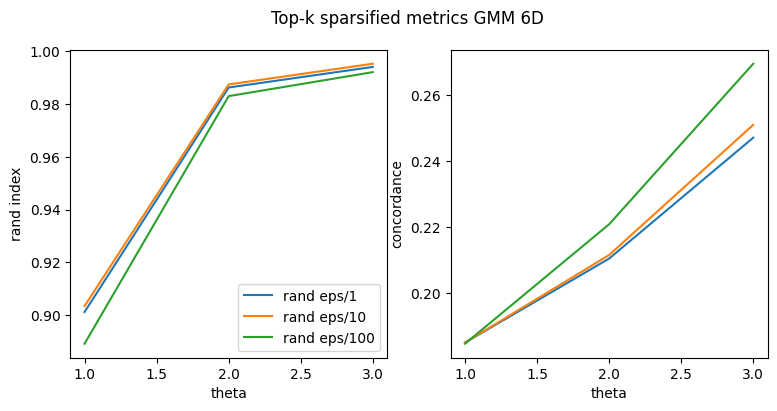

In [226]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))

for i, eps_times in enumerate(eps_times_list):
    ax[0].plot(thetas, rand_topk[:, i].mean(-1), label=f"rand eps/{eps_times}")
    ax[1].plot(thetas, concordances_topk[:, i].mean(-1), label=f"concordance eps/{eps_times}")

ax[0].set_xlabel("theta")
ax[0].set_ylabel("rand index")
ax[0].legend()
ax[1].set_xlabel("theta")
ax[1].set_ylabel("concordance")


fig.suptitle(f"Top-k sparsified metrics GMM 6D")
fig.savefig(os.path.join(fig_path, f"gmm_topk_metrics_6d.png"))

In [227]:
# EOT
sparsify = None # "topk" # None # "topk" # None
t = 0

In [228]:
concordances_eot0 = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
rand_eot0 = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
for i, theta in enumerate(thetas):
    for j, eps_times in enumerate(eps_times_list):
        metrics_path = os.path.join(res_path,
                                    f"{dataset}_theta_{theta}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}_metrics.npz")
        metrics = np.load(metrics_path)
        concordances_eot0[i, j] = metrics["concordance"]
        rand_eot0[i, j] = metrics["rand"]


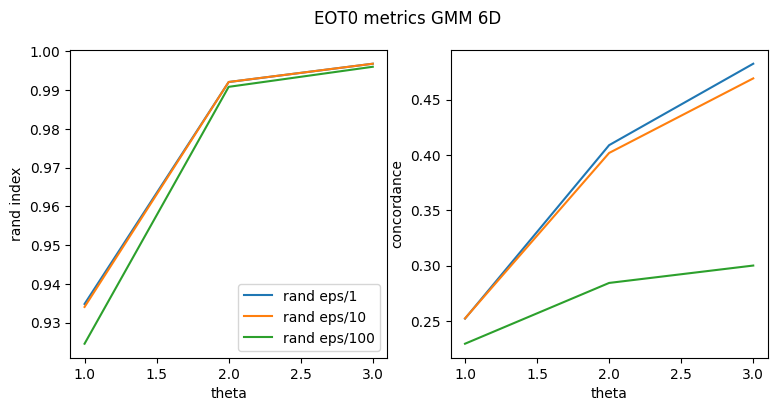

In [229]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))

for i, eps_times in enumerate(eps_times_list):
    ax[0].plot(thetas, rand_eot0[:, i].mean(-1), label=f"rand eps/{eps_times}")
    ax[1].plot(thetas, concordances_eot0[:, i].mean(-1), label=f"concordance eps/{eps_times}")

ax[0].set_xlabel("theta")
ax[0].set_ylabel("rand index")
ax[0].legend()
ax[1].set_xlabel("theta")
ax[1].set_ylabel("concordance")

fig.suptitle(f"EOT{t} metrics GMM 6D")
fig.savefig(os.path.join(fig_path, f"gmm_EOT{t}_metrics_6d.png"))

In [230]:
# compare metrics

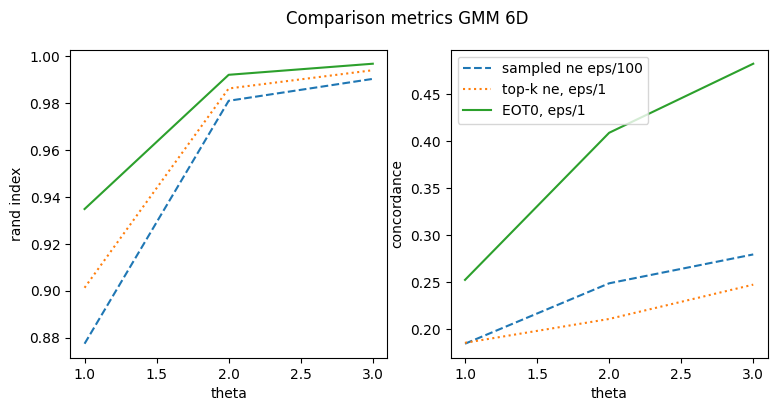

In [231]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].plot(thetas, rand_sample[:, -1].mean(-1), label=f"sampled ne eps / 100", linestyle="dashed")
ax[0].plot(thetas, rand_topk[:, 0].mean(-1), label=f"top-k ne eps/1", linestyle="dotted")
ax[0].plot(thetas, rand_eot0[:, 0].mean(-1), label=f"EOT0 eps/1", linestyle="solid")

ax[1].plot(thetas, concordances_sample[:, -1].mean(-1), label=f"sampled ne eps/100", linestyle="dashed")
ax[1].plot(thetas, concordances_topk[:, 0].mean(-1), label=f"top-k ne, eps/1", linestyle="dotted")
ax[1].plot(thetas, concordances_eot0[:, 0].mean(-1), label=f"EOT0, eps/1", linestyle="solid")

ax[0].set_xlabel("theta")
ax[0].set_ylabel("rand index")
ax[1].legend()
ax[1].set_xlabel("theta")
ax[1].set_ylabel("concordance")

fig.suptitle(f"Comparison metrics GMM 6D")
fig.savefig(os.path.join(fig_path, f"gmm_comparison_metrics_6d.png"))

In [1]:
# test diag settings

In [2]:
## 2D,


In [8]:
theta = 3.0
eps_times = 1
seed = 0

In [4]:
clean1, clean2, clusters0, clusters1, = make_joint_gmm(n0=n0, n1=n1, p=1000, q=6, theta=3.0,seed=0, clean=True)

In [5]:
clusters = np.concatenate([clusters0, clusters1])

colorj = np.array([plt.get_cmap("tab10")(i) for i in clusters])
colors = np.array(colors)

In [6]:
diag_tsne = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm/gmm_theta_3_seed_0_epstimes_1_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["embd"]

int64


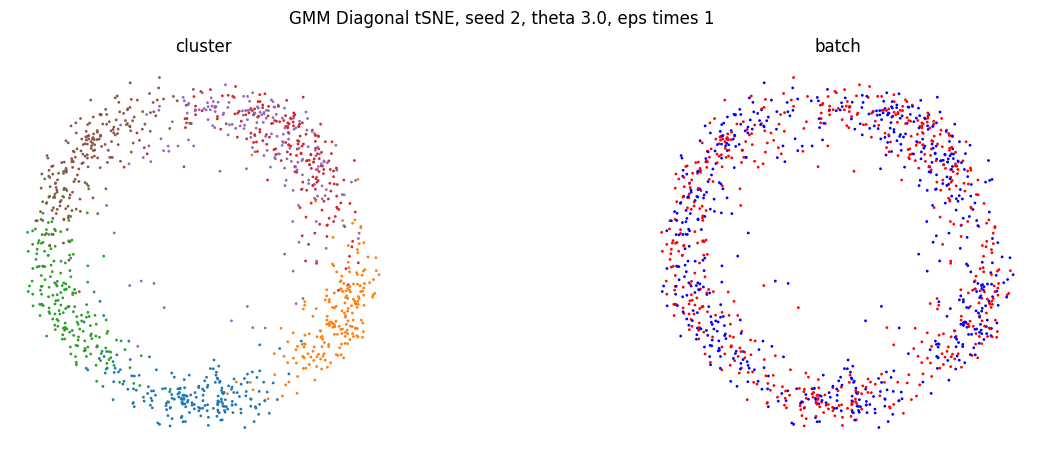

In [75]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

order = np.random.permutation(len(colorj))
print(order.dtype)

ax[0].scatter(*diag_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("cluster")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*diag_tsne[order].T, s=1, c=colors[order])
ax[1].set_title("batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

fig.suptitle(f"GMM Diagonal tSNE, seed {seed}, theta {theta}, eps times {eps_times}")
fig.savefig(os.path.join(fig_path, f"gmm_seed_{seed}_theta_{theta}_diag_tsne_eps_times_{eps_times}.png"))

In [37]:
# different seed for order of clusters
diag_tsne1 = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm/gmm_theta_3_seed_1_epstimes_1_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["embd"]

int64


(np.float64(-0.10127084782829679),
 np.float64(0.10454475600583023),
 np.float64(-0.10531212817748851),
 np.float64(0.10482373543150988))

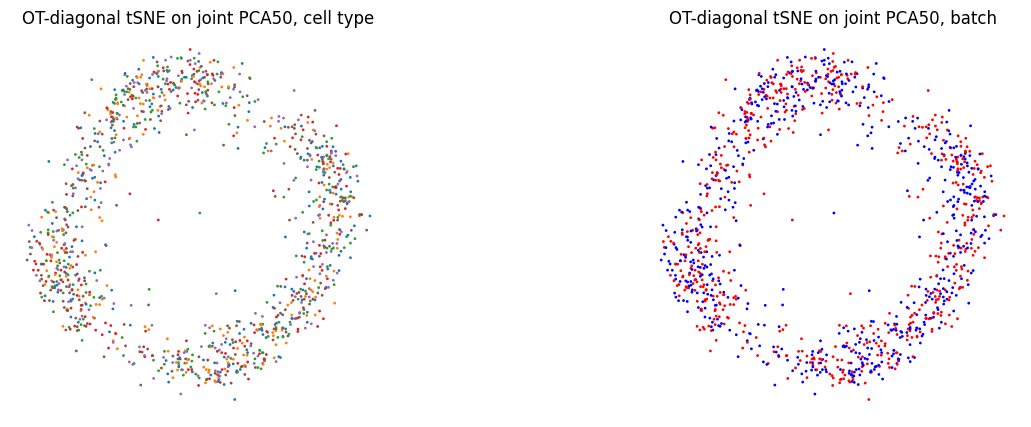

In [39]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

order = np.random.permutation(len(colorj))
print(order.dtype)

ax[0].scatter(*diag_tsne1[order].T, s=1, c=colorj[order])
ax[0].set_title("OT-diagonal tSNE on joint PCA50, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*diag_tsne1[order].T, s=1, c=colors[order])
ax[1].set_title("OT-diagonal tSNE on joint PCA50, batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

In [19]:
# no diagonal
no_diag_tsne = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm/gmm_theta_3_seed_0_epstimes_1_diag_False_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["embd"]

int64


(np.float64(-0.10340659545076156),
 np.float64(0.1036267924338116),
 np.float64(-0.11123009416509295),
 np.float64(0.1002987006775159))

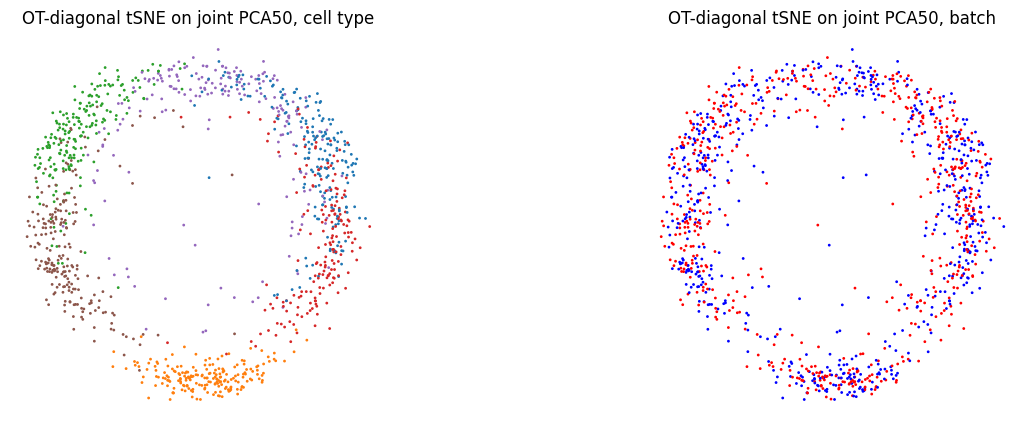

In [20]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

order = np.random.permutation(len(colorj))
print(order.dtype)

ax[0].scatter(*no_diag_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("Non-diagonal tSNE on joint PCA50, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*no_diag_tsne[order].T, s=1, c=colors[order])
ax[1].set_title("Non-diagonal tSNE on joint PCA50, batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

In [10]:
P = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm/gmm_theta_3_seed_0_epstimes_1_diag_False_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["P_sparse"]

In [11]:
P.min(), P.max()

(np.float64(2.6331905037674953e-06), np.float64(2.9650578286990733e-06))

In [24]:
clusters0.shape

(600,)

In [31]:
sorted_idx0 = np.argsort(clusters0)
sorted_idx1 = np.argsort(clusters1)
sorted_idx = np.concatenate([sorted_idx0, sorted_idx1 + n0])

In [25]:
P.shape

(600, 600)

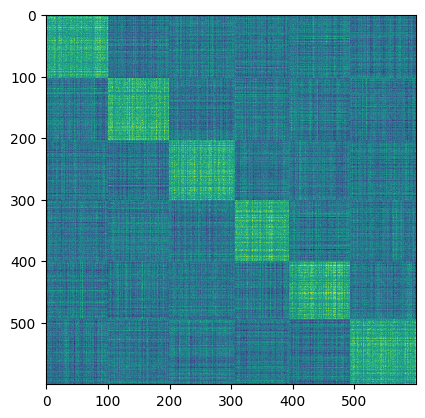

In [14]:
plt.imshow(P[np.ix_(sorted_idx0, sorted_idx1)], interpolation="none")

In [15]:
from ne_aligned_utils.utils import get_bipartite_graph

In [27]:
g = get_bipartite_graph(P, diag=True).toarray()
#np.fill_diagonal(g, g.max())

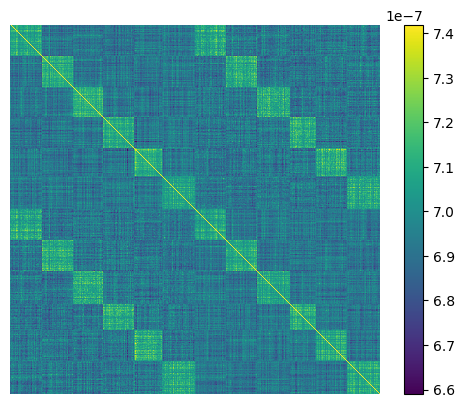

In [80]:
g_plot = g.copy()

np.fill_diagonal(g_plot, g_plot.max())
plt.imshow(g_plot[np.ix_(sorted_idx, sorted_idx)], interpolation="none")
plt.axis('off')
plt.colorbar()
plt.savefig(os.path.join(fig_path, f"gmm_full_affinity_matrix.png"), dpi=300)

In [61]:
g[:n0, :n0].argsort(axis=1)[:, -15:].shape

(600, 15)

In [62]:
g_sparse = sparsify_affinities(g, n0, n1, k=15)

In [63]:
g_sparse.sum(1)

array([53., 30., 43., ..., 41., 31., 45.], shape=(1200,))

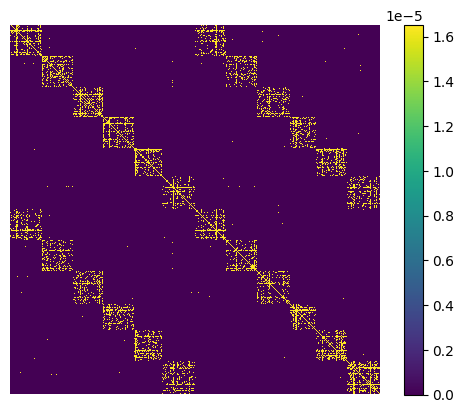

In [81]:
g_plot = g_sparse.copy()
np.fill_diagonal(g_plot, g_plot.max())
plt.imshow(g_plot[np.ix_(sorted_idx, sorted_idx)], interpolation="none")
plt.colorbar()
plt.axis('off')
plt.savefig(os.path.join(fig_path, f"gmm_diag_sparse_affinity_matrix.png"), dpi=300)

In [65]:
g_sparse /= g_sparse.sum()



In [66]:
embd_dim = 2
seed = 2
init = np.random.randn(n0+n1 , embd_dim)
#init = PCA(n_components=embd_dim).fit_transform(clean1)
init /= init.std(0)[0]
init /= 10000

In [67]:
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=seed,
                early_exaggeration_iter=66,
                n_iter=133)
affinities = Affinities()
affinities.P = sp.csr_matrix(g_sparse)

embd_diag_sparse = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=133,
     random_state=2, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=100.00 for 66 iterations...
Iteration   50, KL divergence 2.0023, 50 iterations in 1.5311 sec
   --> Time elapsed: 1.97 seconds
===> Running optimization with exaggeration=1.00, lr=1200.00 for 133 iterations...
Iteration   50, KL divergence 1.3032, 50 iterations in 1.2464 sec
Iteration  100, KL divergence 1.2794, 50 iterations in 1.1992 sec
   --> Time elapsed: 3.24 seconds


int64


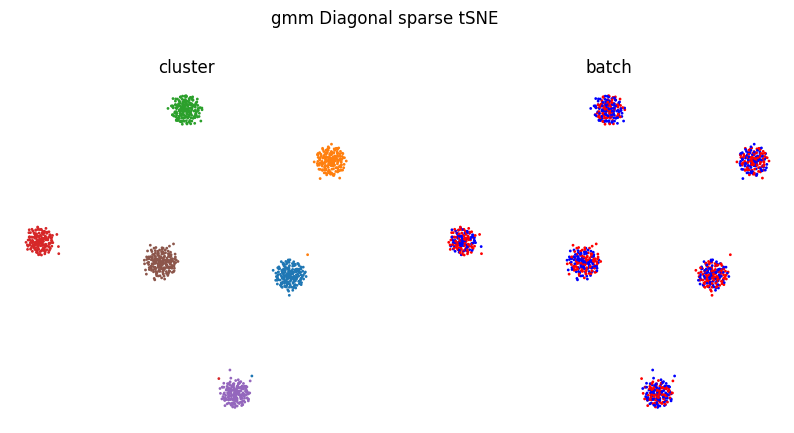

In [72]:
fig, ax = plt.subplots(1,2, figsize=(10,5))

order = np.random.permutation(len(colorj))
print(order.dtype)

ax[0].scatter(*embd_diag_sparse[order].T, s=1, c=colorj[order])
ax[0].set_title(f"cluster")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*embd_diag_sparse[order].T, s=1, c=colors[order])
ax[1].set_title(f"batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

fig.suptitle(f"{dataset} Diagonal sparse tSNE")
fig.savefig(os.path.join(fig_path, f"gmm_diag_sparse_tsne.png"))

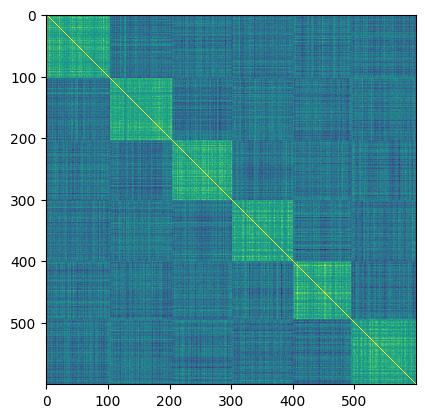

In [140]:
g_plot = g.copy()
np.fill_diagonal(g_plot, g_plot.max())
plt.imshow(g_plot[np.ix_(sorted_idx0, sorted_idx0)], interpolation="none")

In [96]:
embd_dim = 2
seed = 2
#init = np.random.randn(n0 , embd_dim)
init = PCA(n_components=embd_dim).fit_transform(clean1)
init /= init.std(0)[0]
init /= 10000

In [97]:
g_single = g[:n0, :n0]

g_single[g_single < 0] = 0

#g_single -= g_single[g_single > 0].min()

g_single /= g_single.sum()
print(g_single.min())

0.0


In [98]:
g_single[np.ix_(sorted_idx0, sorted_idx0)][:100, :100].mean()

np.float64(3.897765480853168e-06)

In [99]:
g_single[np.ix_(sorted_idx0, sorted_idx0)][:100, 100:].mean()


np.float64(2.553765000790582e-06)

(array([1.66849553e+03, 2.48251910e+04, 1.63057517e+05, 5.84023995e+05,
        9.11301921e+05, 6.16382696e+05, 1.82927782e+05, 3.54934503e+04,
        7.53351011e+03, 8.08967529e+02]),
 array([7.53263194e-07, 1.14882913e-06, 1.54439507e-06, 1.93996101e-06,
        2.33552695e-06, 2.73109289e-06, 3.12665883e-06, 3.52222477e-06,
        3.91779071e-06, 4.31335664e-06, 4.70892258e-06]),
 <BarContainer object of 10 artists>)

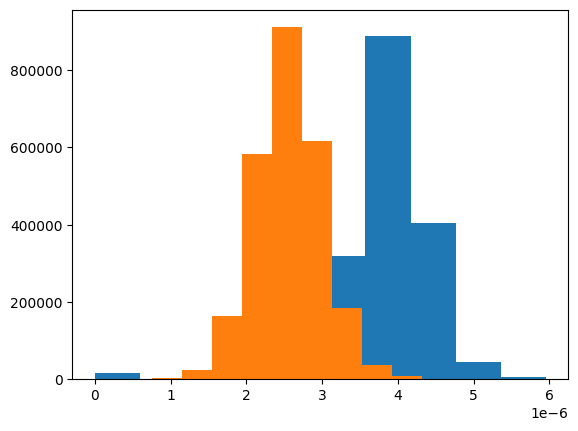

In [100]:
plt.hist(g_single[np.ix_(sorted_idx0, sorted_idx0)][:100, :100].flatten(), density=True)
plt.hist(g_single[np.ix_(sorted_idx0, sorted_idx0)][:100, 100:].flatten(), density=True)


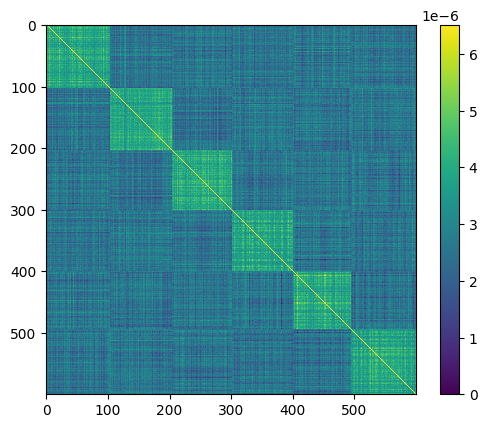

In [101]:
g_plot = g_single.copy()
np.fill_diagonal(g_plot, g_plot.max())
plt.imshow(g_plot[np.ix_(sorted_idx0, sorted_idx0)], interpolation="none")
plt.colorbar()

In [102]:
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=seed,
                early_exaggeration_iter=66,
                n_iter=133)
affinities = Affinities()
affinities.P = sp.csr_matrix(g_single)

embd_single = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=133,
     random_state=2, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=50.00 for 66 iterations...
Iteration   50, KL divergence -2.1012, 50 iterations in 0.5752 sec
   --> Time elapsed: 0.64 seconds
===> Running optimization with exaggeration=1.00, lr=600.00 for 133 iterations...
Iteration   50, KL divergence 0.0191, 50 iterations in 0.6230 sec
Iteration  100, KL divergence 0.0191, 50 iterations in 0.5543 sec
   --> Time elapsed: 1.54 seconds


In [103]:
g_single -= g_single[g_single > 0].min()
g_single[g_single< 0] = 0

g_single /= g_single.sum()


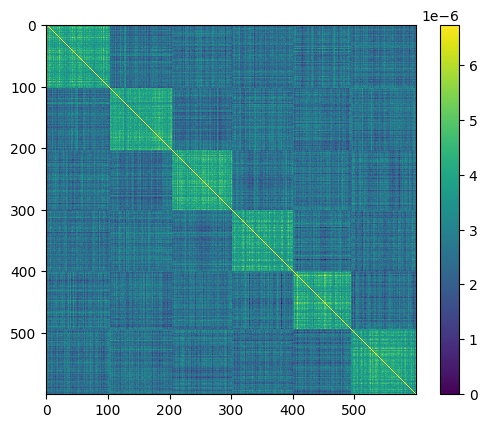

In [104]:
g_plot = g_single.copy()
np.fill_diagonal(g_plot, g_plot.max())
plt.imshow(g_plot[np.ix_(sorted_idx0, sorted_idx0)], interpolation="none")
plt.colorbar()

(array([4.00000e+01, 1.68200e+03, 3.56320e+04, 1.52262e+05, 1.03878e+05,
        3.89240e+04, 2.29400e+04, 3.78200e+03, 2.48000e+02, 6.12000e+02]),
 array([0.00000000e+00, 6.73053713e-07, 1.34610743e-06, 2.01916114e-06,
        2.69221485e-06, 3.36526857e-06, 4.03832228e-06, 4.71137599e-06,
        5.38442971e-06, 6.05748342e-06, 6.73053713e-06]),
 <BarContainer object of 10 artists>)

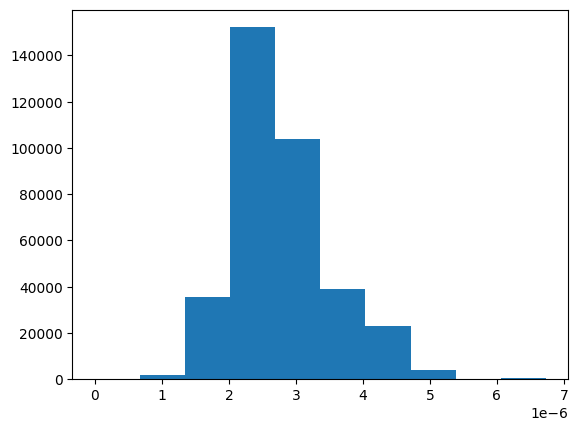

In [105]:
plt.hist(g_plot.flatten())

In [106]:
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=seed,
                early_exaggeration_iter=66,
                n_iter=133)
affinities = Affinities()
affinities.P = sp.csr_matrix(g_single)

embd_min = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=133,
     random_state=2, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=50.00 for 66 iterations...
Iteration   50, KL divergence -2.4608, 50 iterations in 0.5686 sec
   --> Time elapsed: 0.64 seconds
===> Running optimization with exaggeration=1.00, lr=600.00 for 133 iterations...
Iteration   50, KL divergence 0.0210, 50 iterations in 0.5638 sec
Iteration  100, KL divergence 0.0207, 50 iterations in 0.5559 sec
   --> Time elapsed: 1.48 seconds


int64


(np.float64(-0.5201249613389748),
 np.float64(0.5155653732163517),
 np.float64(-0.522941989438647),
 np.float64(0.5357106308769222))

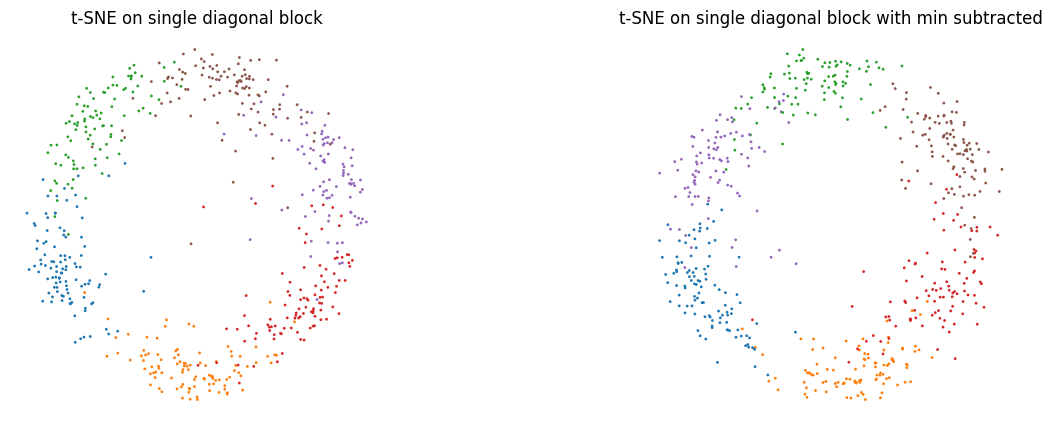

In [107]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

order = np.random.permutation(n0)
print(order.dtype)

ax[0].scatter(*embd_single[order].T, s=1, c=colorj[order])
ax[0].set_title("t-SNE on single diagonal block")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*embd_min[order].T, s=1, c=colorj[order])
ax[1].set_title("t-SNE on single diagonal block with min subtracted")
ax[1].set_aspect("equal")
ax[1].axis("off")

In [191]:
from sklearn.manifold import spectral_embedding

In [192]:
spec_embd0 = spectral_embedding(g_single, n_components=embd_dim)

int64


(np.float64(-2.528875373686679),
 np.float64(2.7340007008833354),
 np.float64(-2.6718320763737635),
 np.float64(2.730177219308497))

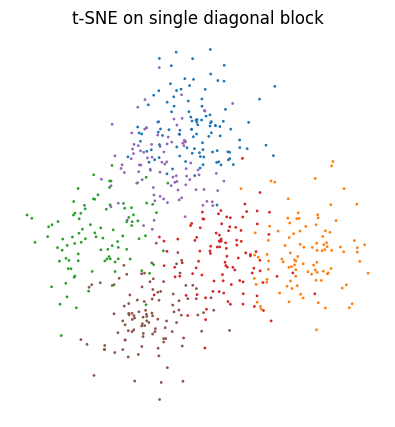

In [193]:
fig, ax = plt.subplots(1,1, figsize=(15,5))

order = np.random.permutation(n0)
print(order.dtype)

ax.scatter(*spec_embd0[order].T, s=1, c=colorj[order])
ax.set_title("t-SNE on single diagonal block")
ax.set_aspect("equal")
ax.axis("off")

In [119]:
## eps = 100

In [34]:
diag100_tsne = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm/gmm_theta_3_seed_0_epstimes_100_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["embd"]

int64


(np.float64(-3.483348875328295),
 np.float64(3.3217936835227917),
 np.float64(-3.0012729597986945),
 np.float64(3.4578818477837405))

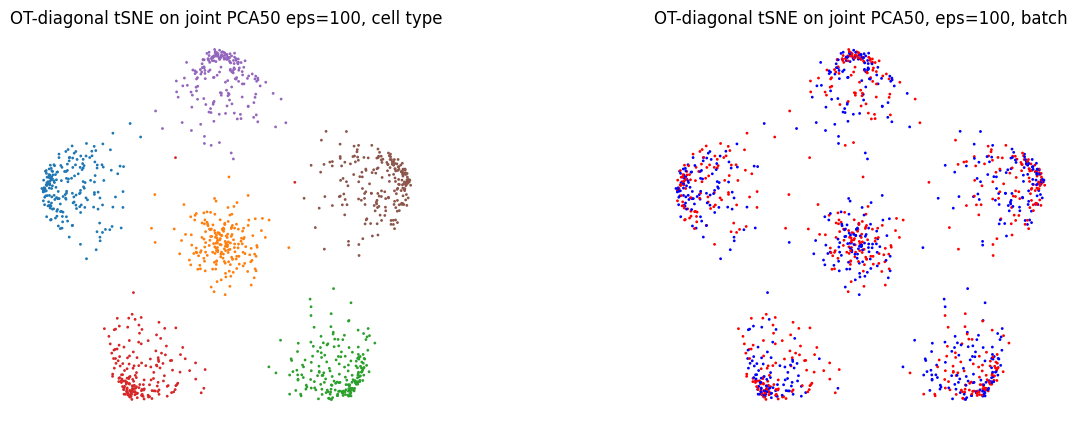

In [35]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

order = np.random.permutation(len(colorj))
print(order.dtype)

ax[0].scatter(*diag100_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("OT-diagonal tSNE on joint PCA50 eps=100, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*diag100_tsne[order].T, s=1, c=colors[order])
ax[1].set_title("OT-diagonal tSNE on joint PCA50, eps=100, batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

In [27]:
no_diag100_tsne = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm/gmm_theta_3_seed_0_epstimes_100_diag_False_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["embd"]


int64


(np.float64(-3.235067234843121),
 np.float64(3.598048658323263),
 np.float64(-3.715885301632363),
 np.float64(3.443058179314232))

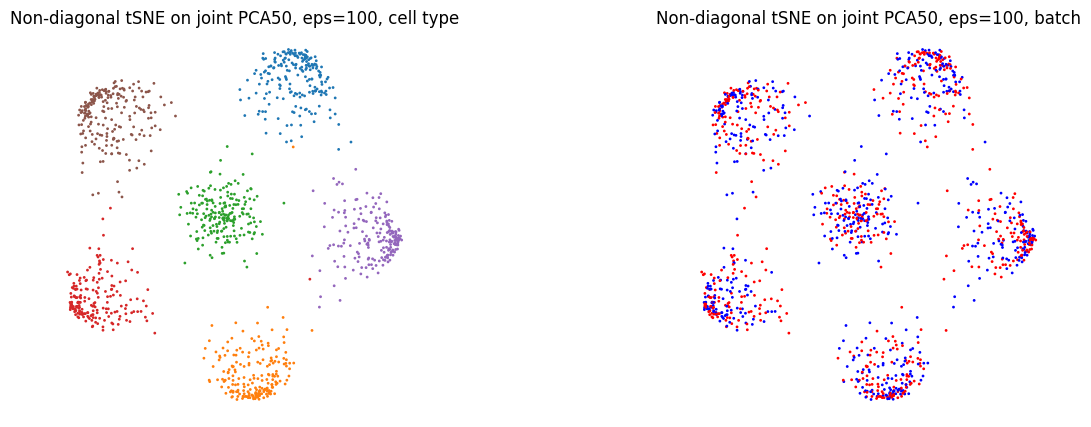

In [31]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

order = np.random.permutation(len(colorj))
print(order.dtype)

ax[0].scatter(*no_diag100_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("Non-diagonal tSNE on joint PCA50, eps=100, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*no_diag100_tsne[order].T, s=1, c=colors[order])
ax[1].set_title("Non-diagonal tSNE on joint PCA50, eps=100, batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

In [241]:
# try near constant similarity
np.random.seed(seed=seed)
P = np.random.uniform(0, 1, size=600**2).reshape(600, 600)

P = 0.5 + P*0.01

np.fill_diagonal(P, 0)
P /= P.sum()

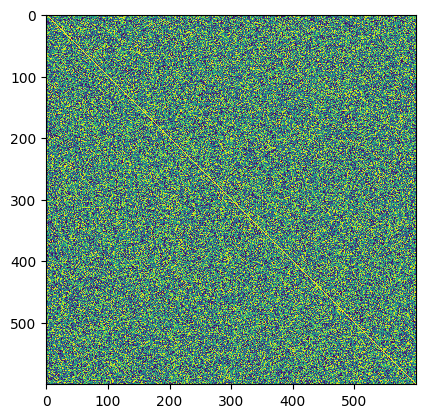

In [243]:
P_plot = P
np.fill_diagonal(P_plot, P_plot.max())
plt.imshow(P, interpolation="none")

In [198]:
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=seed,
                early_exaggeration_iter=66,
                n_iter=133)
affinities = Affinities()
affinities.P = sp.csr_matrix(P)

embd_random = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=133,
     random_state=2, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=50.00 for 66 iterations...
Iteration   50, KL divergence -1.6815, 50 iterations in 0.5060 sec
   --> Time elapsed: 0.57 seconds
===> Running optimization with exaggeration=1.00, lr=600.00 for 133 iterations...
Iteration   50, KL divergence 0.0000, 50 iterations in 0.8213 sec
Iteration  100, KL divergence 0.0000, 50 iterations in 0.9390 sec
   --> Time elapsed: 2.33 seconds


int64


(np.float64(-0.024734170858810654),
 np.float64(0.029457839923230828),
 np.float64(-0.020023718790698055),
 np.float64(0.03340013700070827))

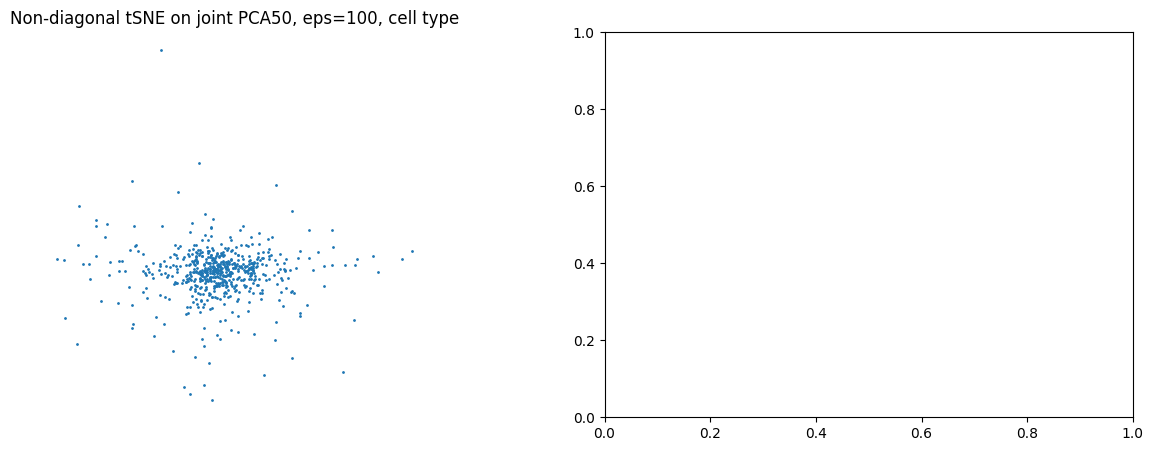

In [200]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

order = np.random.permutation(len(colorj))
print(order.dtype)

ax[0].scatter(*embd_random.T, s=1, )
ax[0].set_title("Non-diagonal tSNE on joint PCA50, eps=100, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")


In [202]:
import scipy.linalg

In [278]:
# block diagonal

blocks = [0.6+ 0.01*np.random.randn(100, 100) for i in range(6)]

block_diag = scipy.linalg.block_diag(*blocks)
P =   np.random.randn(600, 600)*0.01+0.595
P[block_diag > 0] = block_diag[block_diag > 0]



In [279]:
P[:100, :100].mean(), P[:100, 100:].mean()

(np.float64(0.6000249947849936), np.float64(0.5950021672362643))

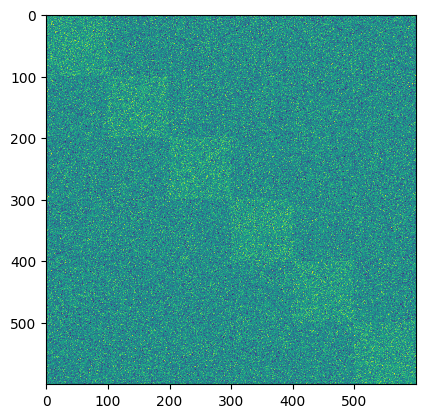

In [280]:
plt.imshow(P, interpolation="none")

In [281]:
np.fill_diagonal(P, 0)
P /= P.sum()

In [282]:
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=seed,
                early_exaggeration_iter=66,
                n_iter=133)
affinities = Affinities()
affinities.P = sp.csr_matrix(P)

embd_block_random = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=133,
     random_state=2, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=50.00 for 66 iterations...
Iteration   50, KL divergence -1.9836, 50 iterations in 0.5402 sec
   --> Time elapsed: 0.61 seconds
===> Running optimization with exaggeration=1.00, lr=600.00 for 133 iterations...
Iteration   50, KL divergence 0.0001, 50 iterations in 0.7935 sec
Iteration  100, KL divergence 0.0002, 50 iterations in 0.8767 sec
   --> Time elapsed: 2.12 seconds


int64


(np.float64(-0.059389704306954956),
 np.float64(0.059043622221420136),
 np.float64(-0.05607371311027372),
 np.float64(0.060989247847412165))

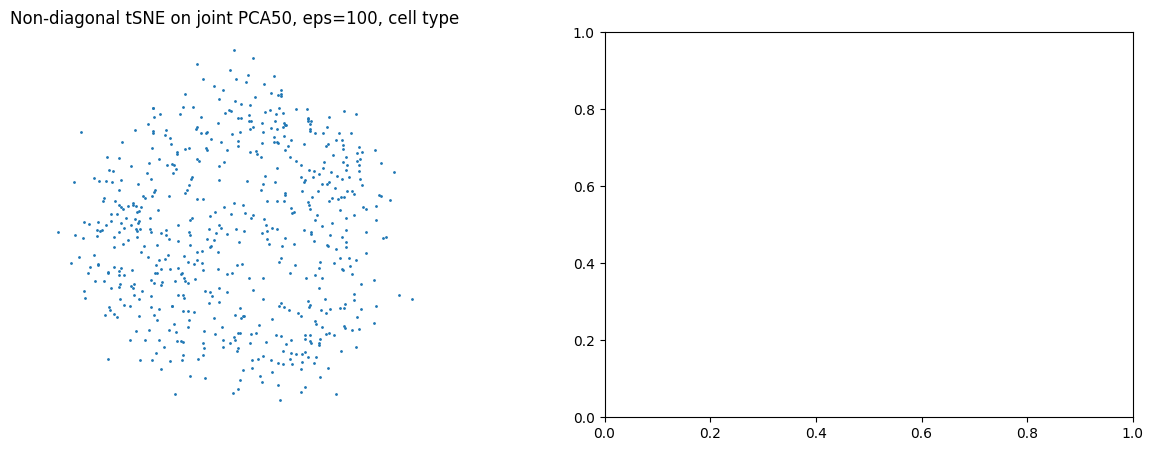

In [283]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

order = np.random.permutation(len(colorj))
print(order.dtype)

ax[0].scatter(*embd_block_random.T, s=1, )
ax[0].set_title("Non-diagonal tSNE on joint PCA50, eps=100, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")
